In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
raw_data = pd.read_csv("../data/raw/housing.csv")

print("Data shape:", raw_data.shape)
print("\nPreview data:")
print(raw_data.head())

Data shape: (20640, 10)

Preview data:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [20]:
print("Data types dan cek null value")
print(raw_data.info())


print("\nMissing values")
missing = raw_data.isnull().sum()
print(missing[missing > 0])

print("\nOcean proximity unique")
print(raw_data['ocean_proximity'].unique())

Data types dan cek null value
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
None

Missing values
total_bedrooms    207
dtype: int64

Ocean proximity unique
<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str


In [21]:
raw_data.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000



Plotting distribution of house prices


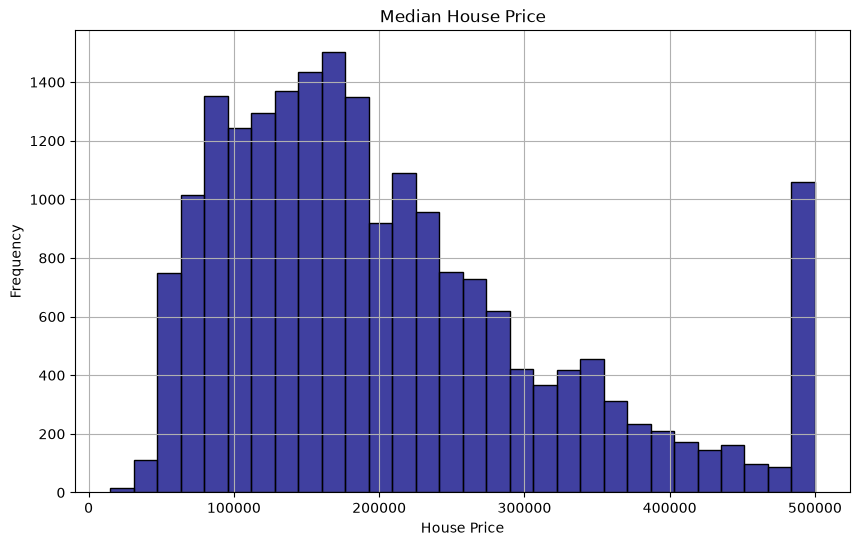

In [22]:
print("\nPlotting distribution of house prices")

plt.figure(figsize=(10,6))
plt.title("Median House Price")
plt.xlabel("House Price")
plt.ylabel("Frequency")

sns.histplot(raw_data["median_house_value"], bins=30, color="navy")

plt.grid(True)
plt.show()

# Exploratory Data Analysis (EDA)

Analisis eksploratif untuk memahami kualitas data, distribusi variabel, hubungan fitur dengan harga rumah, serta perbedaan harga berdasarkan kedekatan dengan laut.

In [23]:
# Ringkasan kualitas data
quality = pd.DataFrame({
    "dtype": raw_data.dtypes.astype(str),
    "missing": raw_data.isna().sum(),
    "missing_pct": (raw_data.isna().mean() * 100).round(2),
    "unique": raw_data.nunique(),
})
print(f"Jumlah baris: {len(raw_data):,}")
print(f"Jumlah duplikasi: {raw_data.duplicated().sum():,}")
display(quality)

Jumlah baris: 20,640
Jumlah duplikasi: 0


,dtype,missing,missing_pct,unique
longitude,float64,0,0.0,844
latitude,float64,0,0.0,862
housing_median_age,float64,0,0.0,52
total_rooms,float64,0,0.0,5926
total_bedrooms,float64,207,1.0,1923
population,float64,0,0.0,3888
households,float64,0,0.0,1815
median_income,float64,0,0.0,12928
median_house_value,float64,0,0.0,3842
ocean_proximity,str,0,0.0,5


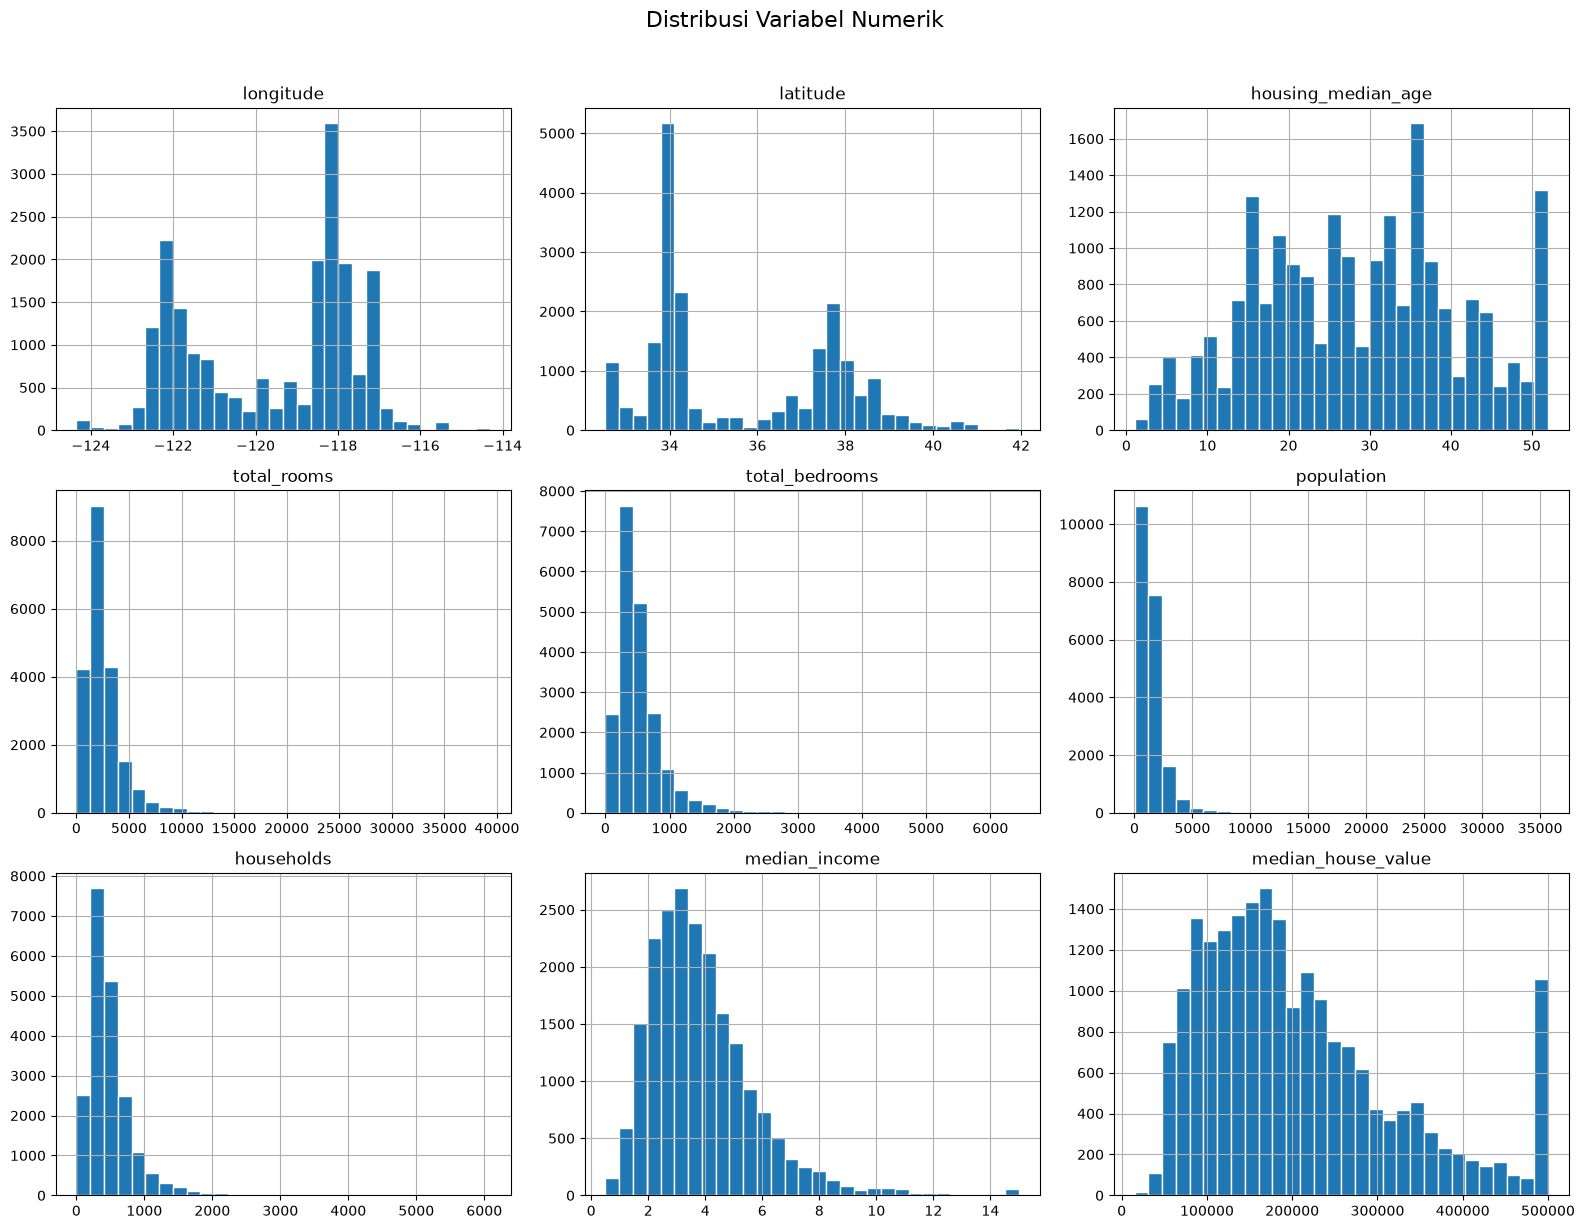

In [24]:
# Distribusi fitur numerik dan target
numeric_columns = raw_data.select_dtypes(include="number").columns
raw_data[numeric_columns].hist(figsize=(16, 12), bins=30, edgecolor="white")
plt.suptitle("Distribusi Variabel Numerik", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

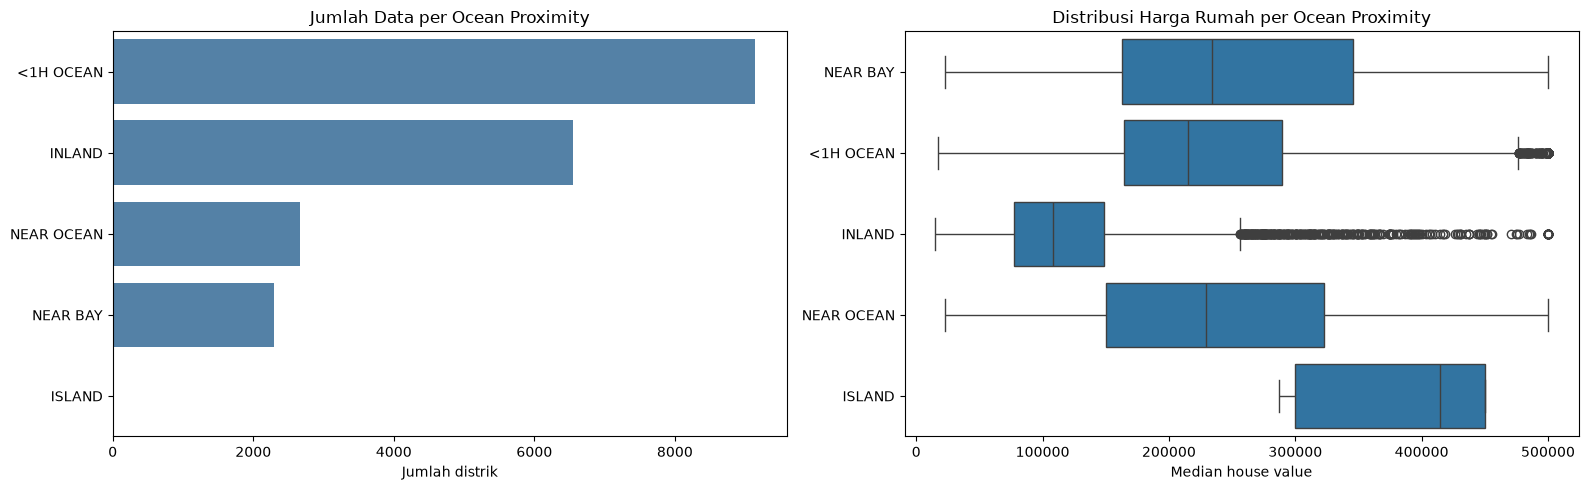

,count,mean,median,min,max
ocean_proximity,,,,,
ISLAND,5,380440.000000,414700.0,287500.0,450000.0
NEAR BAY,2290,259212.311790,233800.0,22500.0,500001.0
NEAR OCEAN,2658,249433.977427,229450.0,22500.0,500001.0
<1H OCEAN,9136,240084.285464,214850.0,17500.0,500001.0
INLAND,6551,124805.392001,108500.0,14999.0,500001.0


In [25]:
# Distribusi kategori dan harga rata-rata per kategori
category_counts = raw_data["ocean_proximity"].value_counts().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0], color="steelblue")
axes[0].set_title("Jumlah Data per Ocean Proximity")
axes[0].set_xlabel("Jumlah distrik")
axes[0].set_ylabel("")
sns.boxplot(data=raw_data, x="median_house_value", y="ocean_proximity", ax=axes[1])
axes[1].set_title("Distribusi Harga Rumah per Ocean Proximity")
axes[1].set_xlabel("Median house value")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()
display(
    raw_data.groupby("ocean_proximity")["median_house_value"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

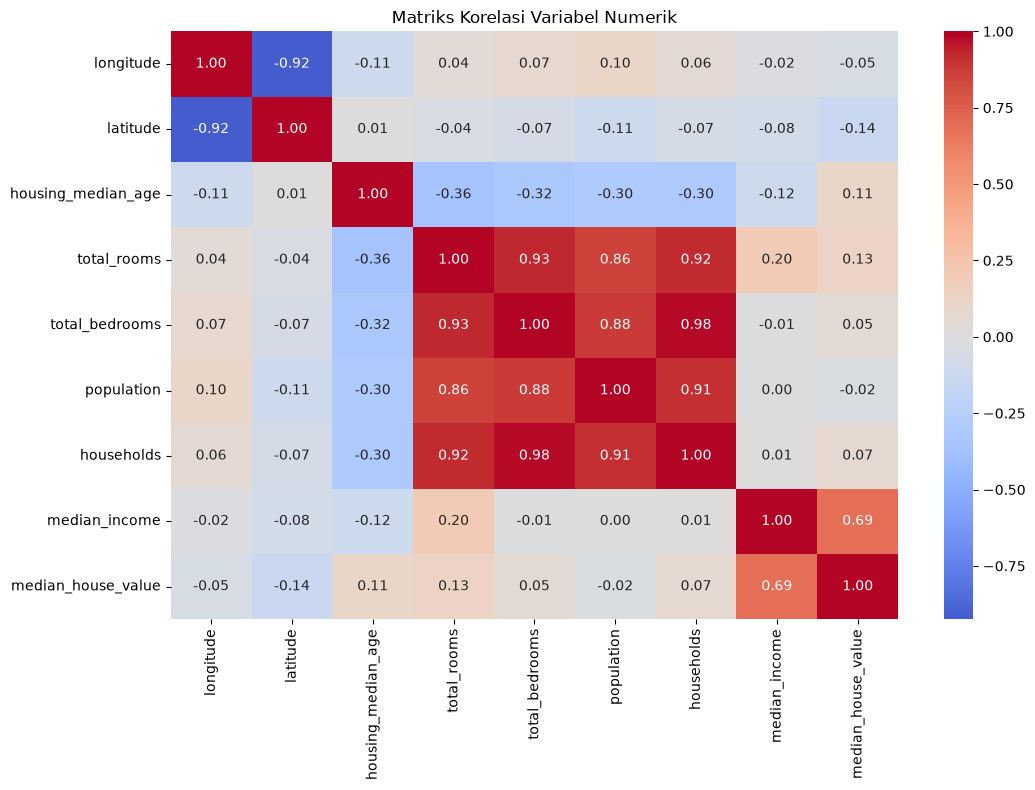

,correlation_with_target
median_income,0.688075
latitude,-0.144160
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
longitude,-0.045967
population,-0.024650


In [26]:
# Korelasi fitur numerik terhadap target
correlation = raw_data[numeric_columns].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

display(correlation["median_house_value"].drop("median_house_value").sort_values(key=abs, ascending=False).to_frame("correlation_with_target"))

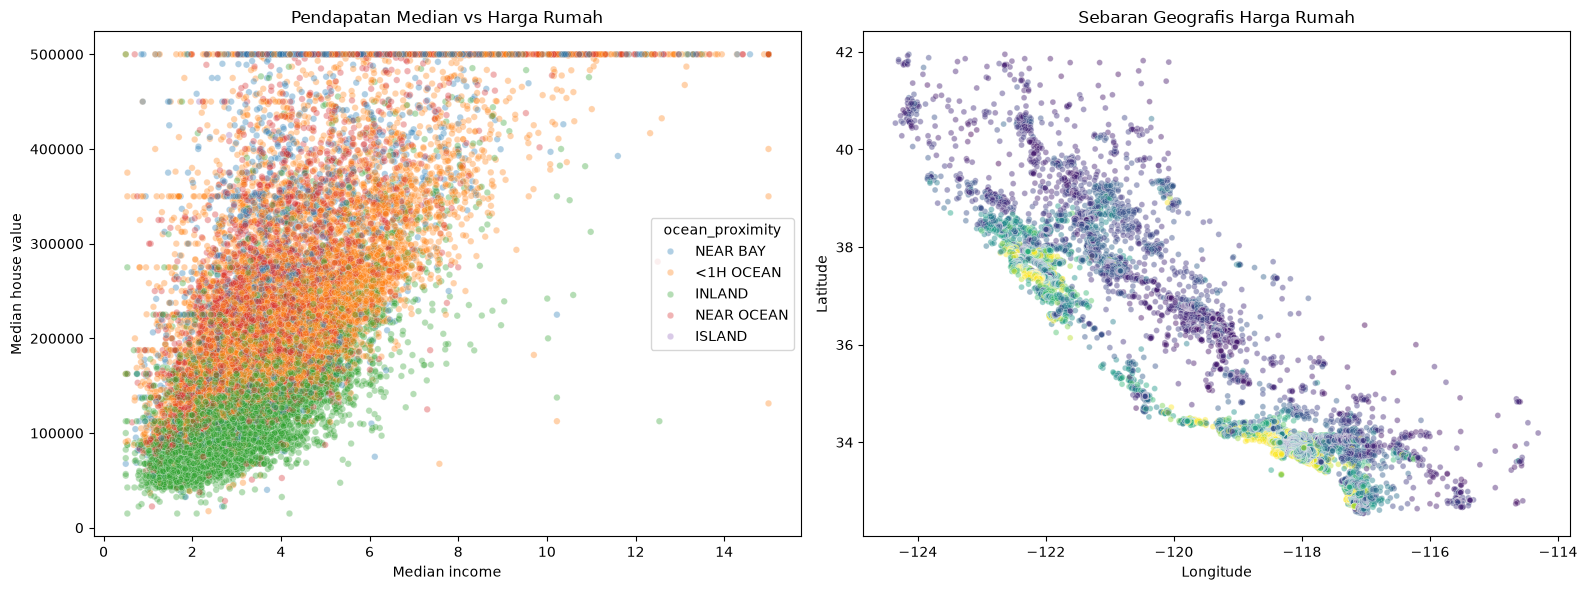

In [27]:
# Hubungan pendapatan, lokasi geografis, dan harga rumah
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=raw_data, x="median_income", y="median_house_value", hue="ocean_proximity", alpha=0.35, s=22, ax=axes[0])
axes[0].set_title("Pendapatan Median vs Harga Rumah")
axes[0].set_xlabel("Median income")
axes[0].set_ylabel("Median house value")
sns.scatterplot(data=raw_data, x="longitude", y="latitude", hue="median_house_value", palette="viridis", alpha=0.45, s=18, ax=axes[1], legend=False)
axes[1].set_title("Sebaran Geografis Harga Rumah")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [28]:
# Pemeriksaan outlier berbasis IQR
outlier_summary = []
for column in numeric_columns:
    q1, q3 = raw_data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((raw_data[column] < lower) | (raw_data[column] > upper)).sum()
    outlier_summary.append({"column": column, "outlier_count": count, "outlier_pct": round(count / len(raw_data) * 100, 2)})

display(pd.DataFrame(outlier_summary).sort_values("outlier_count", ascending=False))

print("Insight awal:")
print(f"- Korelasi terkuat dengan harga: {correlation['median_house_value'].drop('median_house_value').abs().idxmax()}.")
print(f"- Kategori dengan rata-rata harga tertinggi: {raw_data.groupby('ocean_proximity')['median_house_value'].mean().idxmax()}.")
print(f"- Kolom dengan missing value: {quality[quality['missing'] > 0].index.tolist()}.")

,column,outlier_count,outlier_pct
3,total_rooms,1287,6.24
4,total_bedrooms,1271,6.16
6,households,1220,5.91
5,population,1196,5.79
8,median_house_value,1071,5.19
7,median_income,681,3.30
0,longitude,0,0.00
1,latitude,0,0.00
2,housing_median_age,0,0.00


Insight awal:
- Korelasi terkuat dengan harga: median_income.
- Kategori dengan rata-rata harga tertinggi: ISLAND.
- Kolom dengan missing value: ['total_bedrooms'].
